In [ ]:
we had 
analytical_sample.parquet
        ↓
       df
        ↓
all feature engineering
        ↓
model

will replace with 
100 merged_chunks
        ↓
process store-by-store
        ↓
process chronological chunks
        ↓
feature engineering
        ↓
save FE chunks
        ↓
training/validation
        ↓
model
 in another notebook 05_chunk_fe

In [1]:
import pandas as pd
import datetime as dt
df = pd.read_parquet(
    "../data/processed/analytical_sample.parquet"
)

df.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,None,None,None,None,0,0,0,NaN
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,None,None,None,None,0,0,0,NaN
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,None,None,None,None,0,0,0,NaN
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,None,None,None,None,0,0,0,NaN
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,None,None,None,None,0,0,0,NaN


In [2]:
df.shape

(1913000, 22)

In [3]:
df["year"]=df["date"].dt.year
df

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,None,None,None,None,0,0,0,NaN
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,None,None,None,None,0,0,0,NaN
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,None,None,None,None,0,0,0,NaN
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,None,None,None,None,0,0,0,NaN
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,None,None,None,None,0,0,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1912995,HOUSEHOLD_1_440_CA_1_validation,HOUSEHOLD_1_440,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1913,1,2016-04-24,11613,...,4,2016,None,None,None,None,0,0,0,14.97
1912996,HOUSEHOLD_1_441_CA_1_validation,HOUSEHOLD_1_441,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1913,5,2016-04-24,11613,...,4,2016,None,None,None,None,0,0,0,2.77
1912997,HOUSEHOLD_1_442_CA_1_validation,HOUSEHOLD_1_442,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1913,0,2016-04-24,11613,...,4,2016,None,None,None,None,0,0,0,8.97
1912998,HOUSEHOLD_1_443_CA_1_validation,HOUSEHOLD_1_443,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1913,0,2016-04-24,11613,...,4,2016,None,None,None,None,0,0,0,2.47


In [4]:
#creating month
df["month"]=df["date"].dt.month
df["day_of_week"]=df["date"].dt.dayofweek

In [5]:
#create a feature to check whether the date is weekend date or not
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

In [6]:
# checking the new features with dates
df[
    [
        "date",
        "year",
        "month",
        "day_of_week",
        "is_weekend"
    ]
].sample(15)

,date,year,month,day_of_week,is_weekend
139144,2011-06-17,2011,6,4,0
1800797,2016-01-03,2016,1,6,1
11566,2011-02-09,2011,2,2,0
1230987,2014-06-12,2014,6,3,0
565966,2012-08-16,2012,8,3,0
624650,2012-10-14,2012,10,6,1
596400,2012-09-16,2012,9,6,1
898101,2013-07-15,2013,7,0,0
975543,2013-09-30,2013,9,0,0
1510554,2015-03-19,2015,3,3,0


In [7]:
# sort the data so that future sales not come before
#Because shift() works according to row order.
df = df.sort_values(
    ["item_id", "store_id", "date"]
).reset_index(drop=True)

In [8]:
df

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price,day_of_week,is_weekend
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,None,None,None,None,0,0,0,NaN,5,1
1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2011-01-30,11101,...,None,None,None,None,0,0,0,NaN,6,1
2,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_3,0,2011-01-31,11101,...,None,None,None,None,0,0,0,NaN,0,0
3,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_4,0,2011-02-01,11101,...,None,None,None,None,1,1,0,NaN,1,0
4,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_5,0,2011-02-02,11101,...,None,None,None,None,1,0,1,NaN,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1912995,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1909,0,2016-04-20,11612,...,None,None,None,None,0,0,0,4.88,2,0
1912996,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1910,2,2016-04-21,11612,...,None,None,None,None,0,0,0,4.88,3,0
1912997,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1911,2,2016-04-22,11612,...,None,None,None,None,0,0,0,4.88,4,0
1912998,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1912,0,2016-04-23,11613,...,None,None,None,None,0,0,0,4.88,5,1


In [8]:
df["sales_lag_1"] = (
    df
    .groupby(["item_id", "store_id"])["sales"]
    .shift(1)
)
# we are just doing  group the data and then take sales then lag or shift

In [9]:
df

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price,day_of_week,is_weekend,sales_lag_1
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,None,None,None,0,0,0,NaN,5,1,NaN
1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2011-01-30,11101,...,None,None,None,0,0,0,NaN,6,1,0.0
2,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_3,0,2011-01-31,11101,...,None,None,None,0,0,0,NaN,0,0,0.0
3,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_4,0,2011-02-01,11101,...,None,None,None,1,1,0,NaN,1,0,0.0
4,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_5,0,2011-02-02,11101,...,None,None,None,1,0,1,NaN,2,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1912995,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1909,0,2016-04-20,11612,...,None,None,None,0,0,0,4.88,2,0,0.0
1912996,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1910,2,2016-04-21,11612,...,None,None,None,0,0,0,4.88,3,0,0.0
1912997,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1911,2,2016-04-22,11612,...,None,None,None,0,0,0,4.88,4,0,2.0
1912998,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1912,0,2016-04-23,11613,...,None,None,None,0,0,0,4.88,5,1,2.0


In [10]:
#Inspect one product-store series
df[(df["item_id"]=="HOBBIES_1_001") &(df["store_id"] == "CA_1")][
    ["date", "sales", "sales_lag_1"]
].head(15)

,date,sales,sales_lag_1
0,2011-01-29,0,NaN
1,2011-01-30,0,0.0
2,2011-01-31,0,0.0
3,2011-02-01,0,0.0
4,2011-02-02,0,0.0
5,2011-02-03,0,0.0
6,2011-02-04,0,0.0
7,2011-02-05,0,0.0
8,2011-02-06,0,0.0
9,2011-02-07,0,0.0


In [11]:
check = df[
    (df["item_id"] == "HOBBIES_1_001") &
    (df["store_id"] == "CA_1")
].copy()

check["expected_lag_1"] = check["sales"].shift(1)

(check["sales_lag_1"] == check["expected_lag_1"]).iloc[1:].all()

True

In [12]:
df["sales_lag_7"] = (
    df
    .groupby(["item_id", "store_id"])["sales"]
    .shift(7)
)

df["sales_lag_28"] = (
    df
    .groupby(["item_id", "store_id"])["sales"]
    .shift(28)
)

In [13]:
df[
    (df["item_id"] == "HOBBIES_1_001") &
    (df["store_id"] == "CA_1")
][
    ["date", "sales", "sales_lag_1", "sales_lag_7", "sales_lag_28"]
].head(35)


,date,sales,sales_lag_1,sales_lag_7,sales_lag_28
0,2011-01-29,0,NaN,NaN,NaN
1,2011-01-30,0,0.0,NaN,NaN
2,2011-01-31,0,0.0,NaN,NaN
3,2011-02-01,0,0.0,NaN,NaN
4,2011-02-02,0,0.0,NaN,NaN
5,2011-02-03,0,0.0,NaN,NaN
6,2011-02-04,0,0.0,NaN,NaN
7,2011-02-05,0,0.0,0.0,NaN
8,2011-02-06,0,0.0,0.0,NaN
9,2011-02-07,0,0.0,0.0,NaN


In [14]:
df["rolling_mean_7"] = (
    df
    .groupby(["item_id", "store_id"])["sales"]
    .transform(lambda x: x.shift(1).rolling(7).mean())
)
# we have used the shift because we dont want to include todays sales in 
# the average

In [15]:
df[
    (df["item_id"] == "HOBBIES_1_001") &
    (df["store_id"] == "CA_1")
][[
        "date",
        "sales",
        "sales_lag_1",
        "sales_lag_7",
        "sales_lag_28",
        "rolling_mean_7"]
].head(15)

,date,sales,sales_lag_1,sales_lag_7,sales_lag_28,rolling_mean_7
0,2011-01-29,0,NaN,NaN,NaN,NaN
1,2011-01-30,0,0.0,NaN,NaN,NaN
2,2011-01-31,0,0.0,NaN,NaN,NaN
3,2011-02-01,0,0.0,NaN,NaN,NaN
4,2011-02-02,0,0.0,NaN,NaN,NaN
5,2011-02-03,0,0.0,NaN,NaN,NaN
6,2011-02-04,0,0.0,NaN,NaN,NaN
7,2011-02-05,0,0.0,0.0,NaN,0.0
8,2011-02-06,0,0.0,0.0,NaN,0.0
9,2011-02-07,0,0.0,0.0,NaN,0.0


In [16]:
df["rolling_mean_28"] = (
    df
    .groupby(["item_id", "store_id"])["sales"]
    .transform(lambda x: x.shift(1).rolling(28).mean())
)

In [17]:
#lets inspect the rolling_mean features 
df[
    (df["item_id"] == "HOBBIES_1_001") &
    (df["store_id"] == "CA_1")
][
    [
        "date",
        "sales",
        "sales_lag_1",
        "sales_lag_7",
        "sales_lag_28",
        "rolling_mean_7",
        "rolling_mean_28"
    ]
].head(35)

,date,sales,sales_lag_1,sales_lag_7,sales_lag_28,rolling_mean_7,rolling_mean_28
0,2011-01-29,0,NaN,NaN,NaN,NaN,NaN
1,2011-01-30,0,0.0,NaN,NaN,NaN,NaN
2,2011-01-31,0,0.0,NaN,NaN,NaN,NaN
3,2011-02-01,0,0.0,NaN,NaN,NaN,NaN
4,2011-02-02,0,0.0,NaN,NaN,NaN,NaN
5,2011-02-03,0,0.0,NaN,NaN,NaN,NaN
6,2011-02-04,0,0.0,NaN,NaN,NaN,NaN
7,2011-02-05,0,0.0,0.0,NaN,0.0,NaN
8,2011-02-06,0,0.0,0.0,NaN,0.0,NaN
9,2011-02-07,0,0.0,0.0,NaN,0.0,NaN


# let's validate the rolling feature mathematically

In [18]:
check = df[
    (df["item_id"] == "HOBBIES_1_001") &
    (df["store_id"] == "CA_1")
].sort_values("date").reset_index(drop=True)

check[
    [
        "date",
        "sales",
        "sales_lag_1",
        "rolling_mean_7"
    ]
].iloc[1127:1145]

,date,sales,sales_lag_1,rolling_mean_7
1127,2014-03-01,1,0.0,0.428571
1128,2014-03-02,0,1.0,0.285714
1129,2014-03-03,0,0.0,0.285714
1130,2014-03-04,1,0.0,0.285714
1131,2014-03-05,0,1.0,0.285714
1132,2014-03-06,0,0.0,0.285714
1133,2014-03-07,0,0.0,0.285714
1134,2014-03-08,0,0.0,0.285714
1135,2014-03-09,1,0.0,0.142857
1136,2014-03-10,0,1.0,0.285714


In [19]:
current_row = 1127
previous_7_sales = check.loc[
    current_row - 7:current_row - 1,
    "sales"
]
previous_7_sales

1120    2
1121    0
1122    0
1123    1
1124    0
1125    0
1126    0
Name: sales, dtype: int64

In [21]:
previous_7_sales.mean()

0.42857142857142855

In [20]:
check.loc[current_row, "rolling_mean_7"]# look at index 1127 the mean value is present

0.42857142857142855

In [21]:
#check the current price
df["sell_price"].isna().sum()

392504

In [22]:
df["sell_price"].isna().mean() * 100#For now, we'll retain the missing values.

20.51772085729221

In [23]:
df["price_available"] = df["sell_price"].notna().astype(int)
df

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,snap_WI,sell_price,day_of_week,is_weekend,sales_lag_1,sales_lag_7,sales_lag_28,rolling_mean_7,rolling_mean_28,price_available
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,0,NaN,5,1,NaN,NaN,NaN,NaN,NaN,0
1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2011-01-30,11101,...,0,NaN,6,1,0.0,NaN,NaN,NaN,NaN,0
2,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_3,0,2011-01-31,11101,...,0,NaN,0,0,0.0,NaN,NaN,NaN,NaN,0
3,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_4,0,2011-02-01,11101,...,0,NaN,1,0,0.0,NaN,NaN,NaN,NaN,0
4,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_5,0,2011-02-02,11101,...,1,NaN,2,0,0.0,NaN,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1912995,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1909,0,2016-04-20,11612,...,0,4.88,2,0,0.0,0.0,0.0,0.000000,0.321429,1
1912996,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1910,2,2016-04-21,11612,...,0,4.88,3,0,0.0,0.0,1.0,0.000000,0.321429,1
1912997,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1911,2,2016-04-22,11612,...,0,4.88,4,0,2.0,0.0,2.0,0.285714,0.357143,1
1912998,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1912,0,2016-04-23,11613,...,0,4.88,5,1,2.0,0.0,0.0,0.571429,0.357143,1


In [26]:
'''
This preserves two separate pieces of information:

sell_price → what price was recorded
price_available → whether a price was recorded'''

'\nThis preserves two separate pieces of information:\n\nsell_price → what price was recorded\nprice_available → whether a price was recorded'

In [24]:
# now creating the feature for price change
df = df.sort_values(
    ["item_id", "store_id", "date"]
).reset_index(drop=True)

In [25]:
df["price_change"] = (
    df
    .groupby(["item_id", "store_id"])["sell_price"]
    .diff()
)
df

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,sell_price,day_of_week,is_weekend,sales_lag_1,sales_lag_7,sales_lag_28,rolling_mean_7,rolling_mean_28,price_available,price_change
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,NaN,5,1,NaN,NaN,NaN,NaN,NaN,0,NaN
1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2011-01-30,11101,...,NaN,6,1,0.0,NaN,NaN,NaN,NaN,0,NaN
2,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_3,0,2011-01-31,11101,...,NaN,0,0,0.0,NaN,NaN,NaN,NaN,0,NaN
3,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_4,0,2011-02-01,11101,...,NaN,1,0,0.0,NaN,NaN,NaN,NaN,0,NaN
4,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_5,0,2011-02-02,11101,...,NaN,2,0,0.0,NaN,NaN,NaN,NaN,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1912995,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1909,0,2016-04-20,11612,...,4.88,2,0,0.0,0.0,0.0,0.000000,0.321429,1,0.0
1912996,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1910,2,2016-04-21,11612,...,4.88,3,0,0.0,0.0,1.0,0.000000,0.321429,1,0.0
1912997,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1911,2,2016-04-22,11612,...,4.88,4,0,2.0,0.0,2.0,0.285714,0.357143,1,0.0
1912998,HOUSEHOLD_1_444_CA_1_validation,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1912,0,2016-04-23,11613,...,4.88,5,1,2.0,0.0,0.0,0.571429,0.357143,1,0.0


In [26]:
df[
    (df["item_id"] == "HOBBIES_1_001") &
    (df["store_id"] == "CA_1")
][
    [
        "date",
        "sell_price",
        "price_available",
        "price_change"
    ]
].tail(30)

,date,sell_price,price_available,price_change
1883,2016-03-26,8.26,1,0.00
1884,2016-03-27,8.26,1,0.00
1885,2016-03-28,8.26,1,0.00
1886,2016-03-29,8.26,1,0.00
1887,2016-03-30,8.26,1,0.00
1888,2016-03-31,8.26,1,0.00
1889,2016-04-01,8.26,1,0.00
1890,2016-04-02,8.26,1,0.00
1891,2016-04-03,8.26,1,0.00
1892,2016-04-04,8.26,1,0.00


In [27]:
#inspect the missing price transitions
price_check = df[
    (df["item_id"] == "HOBBIES_1_001") &
    (df["store_id"] == "CA_1")
][
    ["date", "sell_price", "price_available", "price_change"]
]

price_check[
    price_check["sell_price"].isna()
].head(20)

,date,sell_price,price_available,price_change
0,2011-01-29,NaN,0,NaN
1,2011-01-30,NaN,0,NaN
2,2011-01-31,NaN,0,NaN
3,2011-02-01,NaN,0,NaN
4,2011-02-02,NaN,0,NaN
5,2011-02-03,NaN,0,NaN
6,2011-02-04,NaN,0,NaN
7,2011-02-05,NaN,0,NaN
8,2011-02-06,NaN,0,NaN
9,2011-02-07,NaN,0,NaN


In [28]:
df["price_changed"] = df["price_change"].ne(0).astype("Int64")
df[
    (df["item_id"] == "HOBBIES_1_001") &
    (df["store_id"] == "CA_1")
][
    [
        "date",
        "sell_price",
        "price_change",
        "price_changed"
    ]
].tail(30)

,date,sell_price,price_change,price_changed
1883,2016-03-26,8.26,0.00,0
1884,2016-03-27,8.26,0.00,0
1885,2016-03-28,8.26,0.00,0
1886,2016-03-29,8.26,0.00,0
1887,2016-03-30,8.26,0.00,0
1888,2016-03-31,8.26,0.00,0
1889,2016-04-01,8.26,0.00,0
1890,2016-04-02,8.26,0.00,0
1891,2016-04-03,8.26,0.00,0
1892,2016-04-04,8.26,0.00,0


In [29]:
#First let's inspect the actual event data.
df[
    ["event_name_1", "event_type_1", "event_name_2", "event_type_2"]
].notna().sum()

event_name_1    154000
event_type_1    154000
event_name_2      4000
event_type_2      4000
dtype: int64

In [30]:
df[
    ["event_name_1", "event_type_1", "event_name_2", "event_type_2"]
].dropna(how="all").head(20)

,event_name_1,event_type_1,event_name_2,event_type_2
8,SuperBowl,Sporting,None,None
16,ValentinesDay,Cultural,None,None
23,PresidentsDay,National,None,None
39,LentStart,Religious,None,None
46,LentWeek2,Religious,None,None
47,StPatricksDay,Cultural,None,None
50,Purim End,Religious,None,None
85,OrthodoxEaster,Religious,Easter,Cultural
87,Pesach End,Religious,None,None
96,Cinco De Mayo,Cultural,None,None


In [31]:
df["is_event"] = (
    df[["event_name_1", "event_name_2"]]
    .notna()
    .any(axis=1)
    .astype("int8")
)

In [32]:
df['is_event'].value_counts()

is_event
0    1759000
1     154000
Name: count, dtype: int64

In [33]:
#inspect a few event dates
df.loc[
    df["is_event"] == 1,
    ["date", "event_name_1", "event_name_2", "is_event"]
].head(10)

,date,event_name_1,event_name_2,is_event
8,2011-02-06,SuperBowl,None,1
16,2011-02-14,ValentinesDay,None,1
23,2011-02-21,PresidentsDay,None,1
39,2011-03-09,LentStart,None,1
46,2011-03-16,LentWeek2,None,1
47,2011-03-17,StPatricksDay,None,1
50,2011-03-20,Purim End,None,1
85,2011-04-24,OrthodoxEaster,Easter,1
87,2011-04-26,Pesach End,None,1
96,2011-05-05,Cinco De Mayo,None,1


# create snap_active feature
- our dataset contains three SNAP columns snap_ca,snap_TX,snap_WI
- Each relates to different state. Since each row already has a state_id,we can create one feature that selects the relevant state's Snap Indicator
- Important concept — Feature relevance: A feature should represent the information relevant to that particular observation.

In [34]:
df["state_id"].value_counts()#due to sample limitation we only have CA state_id now 

state_id
CA    1913000
Name: count, dtype: int64

In [35]:
# step-1now moving towards actual forcasting problem
expected_features = [
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "price_available",
    "price_change",
    "price_changed",
    "is_event"
]

available = [col for col in expected_features if col in df.columns]
missing = [col for col in expected_features if col not in df.columns]

print("Available features:", available)
print("Missing features:", missing)
'''
all columns are present in dataset 
'''

Available features: ['sales_lag_1', 'sales_lag_7', 'sales_lag_28', 'rolling_mean_7', 'rolling_mean_28', 'price_available', 'price_change', 'price_changed', 'is_event']
Missing features: []


'\nall columns are present in dataset \n'

# Defining our forecasting model 
Our current lag features are aligned with the same date's sales. For a row dated February 10, for example:
- sales_lag_1 contains sales from February 9.
- sales_lag_7 contains sales from seven days earlier.
- rolling_mean_7 uses the previous seven days, excluding February 10.
- sales contains the actual sales on February 10.
Therefore, our forecasting problem is:
At the start of a day, predict that day's demand using historical sales and information available in advance.


One assumption for this project model : today's price must be known or planned before the forecast is made.

In [39]:
df.columns.tolist()

['id',
 'item_id',
 'dept_id',
 'cat_id',
 'store_id',
 'state_id',
 'd',
 'sales',
 'date',
 'wm_yr_wk',
 'weekday',
 'wday',
 'month',
 'year',
 'event_name_1',
 'event_type_1',
 'event_name_2',
 'event_type_2',
 'snap_CA',
 'snap_TX',
 'snap_WI',
 'sell_price',
 'day_of_week',
 'is_weekend',
 'sales_lag_1',
 'sales_lag_7',
 'sales_lag_28',
 'rolling_mean_7',
 'rolling_mean_28',
 'price_available',
 'price_change',
 'price_changed',
 'is_event']

# Target and Feature Definition

In [36]:
target_col = "sales"
feature_cols = [
    # Product information
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id",

    # Time features
    "year",
    "month",
    "day_of_week",
    "is_weekend",

    # Historical demand
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_28",
    "rolling_mean_7",
    "rolling_mean_28",

    # Price features
    "sell_price",
    "price_available",
    "price_change",
    "price_changed",

    # Event features
    "event_name_1",
    "event_type_1",
    "event_name_2",
    "event_type_2",
    "is_event"
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]
print("Target:", target_col)
print("Number of input features:", len(feature_cols))
print("Missing features:", missing_features)

Target: sales
Number of input features: 23
Missing features: []


# Check missing values before modeling
Some missing values are expected in our dataset:
- sales_lag_28 and rolling_mean_28: the earliest observations in each product-store series don't have enough history.
- sell_price: some observations have no recorded price.
- price_change: unavailable when the current or previous price cannot be compared.
- Event columns: NaN generally means no event is recorded in that event slot.

In [37]:
# Missing values in input features
missing_counts = (
    df[feature_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("Missing values in input features:")
print(missing_counts[missing_counts > 0])

# Missing values in the target
print("\nMissing target values:", df[target_col].isna().sum())


Missing values in input features:
event_type_2       1909000
event_name_2       1909000
event_type_1       1759000
event_name_1       1759000
price_change        393504
sell_price          392504
sales_lag_28         28000
rolling_mean_28      28000
sales_lag_7           7000
rolling_mean_7        7000
sales_lag_1           1000
dtype: int64

Missing target values: 0


In [42]:
df["price_changed"] = pd.Series(
    pd.NA,
    index=df.index,
    dtype="Int8"
)
valid_price_change = df["price_change"].notna()

df.loc[valid_price_change, "price_changed"] = (
    df.loc[valid_price_change, "price_change"]
    .ne(0)
    .astype("int8")
)

In [43]:
print(df["price_changed"].value_counts(dropna=False))
print(
    "Missing price_changed:",
    df["price_changed"].isna().sum()
)
#The counts add up to 1,913,000, so no observations have disappeared.

price_changed
0       1518028
<NA>     393504
1          1468
Name: count, dtype: Int64
Missing price_changed: 393504


# Prepare the training and validation datasets

- 1. Remove observations without sufficient sales history
Our lag and rolling features require historical observations. The first 28 days of each product-store series do not have a complete 28-day history.
For this initial baseline, we'll exclude those rows. We will not drop rows merely because their price or event fields are missing.

In [38]:
history_cols = [
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]
df_model = df.dropna(subset=history_cols).copy()

print("Original shape:", df.shape)
print("Modeling shape:", df_model.shape)

Original shape: (1913000, 33)
Modeling shape: (1885000, 33)


In [39]:
df_model.columns.tolist()

['id',
 'item_id',
 'dept_id',
 'cat_id',
 'store_id',
 'state_id',
 'd',
 'sales',
 'date',
 'wm_yr_wk',
 'weekday',
 'wday',
 'month',
 'year',
 'event_name_1',
 'event_type_1',
 'event_name_2',
 'event_type_2',
 'snap_CA',
 'snap_TX',
 'snap_WI',
 'sell_price',
 'day_of_week',
 'is_weekend',
 'sales_lag_1',
 'sales_lag_7',
 'sales_lag_28',
 'rolling_mean_7',
 'rolling_mean_28',
 'price_available',
 'price_change',
 'price_changed',
 'is_event']

# Split chronologically

In [40]:
import numpy as np
import pandas as pd

# 1. Get the eligible dates in chronological order
unique_dates = np.sort(df_model["date"].unique())

# 2. Calculate the 80/20 cutoff
split_idx = int(len(unique_dates) * 0.8)
split_date = pd.Timestamp(unique_dates[split_idx])

# 3. Split rows by date
train_df = df_model[
    df_model["date"] < split_date
].copy()
valid_df = df_model[
    df_model["date"] >= split_date
].copy()
# 4. Select input features and target
X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_valid = valid_df[feature_cols]
y_valid = valid_df[target_col]

# 5. Check the results
print("Cutoff date:", split_date)

print("\nX_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_valid:", X_valid.shape)
print("y_valid:", y_valid.shape)

print("\nTotal rows preserved:",
      len(train_df) + len(valid_df) == len(df_model))

print("Chronological split valid:",
      train_df["date"].max() < valid_df["date"].min())

print("Feature count correct:",
      X_train.shape[1] == len(feature_cols)
      and X_valid.shape[1] == len(feature_cols))

Cutoff date: 2015-04-14 00:00:00

X_train: (1508000, 23)
y_train: (1508000,)

X_valid: (377000, 23)
y_valid: (377000,)

Total rows preserved: True
Chronological split valid: True
Feature count correct: True


## What does chronologically mean?
Chronologically means arranging data in time order, from oldest to newest.
For our project, the dates start in January 2011 and continue until April 2016.
For example:
Date	Sales	Purpose
Jan 29, 2011	0	Training
Jan 30, 2011	2	Training
Jan 31, 2011	1	Training
...	...	...
Early April 2015	3	Around the split
...	...	...
April 24, 2016	4	Validation

Why do we split this way?
Imagine you're building a model today to predict tomorrow's demand.
You can use past data to learn patterns, but you cannot use tomorrow's actual sales to train the model before predicting them.
So our approach is:
Training data — Earlier dates
Approximately 80% of the dates. The model learns from historical demand patterns.

Train the model

Validation data — Later dates
Approximately 20% of the dates. We test how well the trained model predicts demand in a later period.

# Separate numerical and categorical features

In [41]:
# Categorical features
categorical_features = [
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id",
    "event_name_1",
    "event_type_1",
    "event_name_2",
    "event_type_2"
]
# Numerical features
numeric_features = [
    col for col in feature_cols
    if col not in categorical_features
]
print("Categorical features:", len(categorical_features))
print(categorical_features)

print("\nNumerical features:", len(numeric_features))
print(numeric_features)

Categorical features: 9
['item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2']

Numerical features: 14
['year', 'month', 'day_of_week', 'is_weekend', 'sales_lag_1', 'sales_lag_7', 'sales_lag_28', 'rolling_mean_7', 'rolling_mean_28', 'sell_price', 'price_available', 'price_change', 'price_changed', 'is_event']


In [42]:
X_train

,item_id,dept_id,cat_id,store_id,state_id,year,month,day_of_week,is_weekend,sales_lag_1,...,rolling_mean_28,sell_price,price_available,price_change,price_changed,event_name_1,event_type_1,event_name_2,event_type_2,is_event
28,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,2011,2,5,1,0.0,...,0.000000,NaN,0,NaN,1,None,None,None,None,0
29,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,2011,2,6,1,0.0,...,0.000000,NaN,0,NaN,1,None,None,None,None,0
30,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,2011,2,0,0,0.0,...,0.000000,NaN,0,NaN,1,None,None,None,None,0
31,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,2011,3,1,0,0.0,...,0.000000,NaN,0,NaN,1,None,None,None,None,0
32,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,2011,3,2,0,0.0,...,0.000000,NaN,0,NaN,1,None,None,None,None,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1912618,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,2015,4,3,0,0.0,...,0.714286,4.88,1,0.0,0,None,None,None,None,0
1912619,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,2015,4,4,0,1.0,...,0.714286,4.88,1,0.0,0,None,None,None,None,0
1912620,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,2015,4,5,1,1.0,...,0.750000,4.88,1,0.0,0,Pesach End,Religious,None,None,1
1912621,HOUSEHOLD_1_444,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,2015,4,6,1,0.0,...,0.607143,4.88,1,0.0,0,OrthodoxEaster,Religious,None,None,1


In [46]:
# Standardize missing event categories
# # Our intended representation for an unrecorded event is "No event".
# Work on independent copies
X_train = X_train.copy()
X_valid = X_valid.copy()
event_categorical_features = [
    "event_name_1",
    "event_type_1",
    "event_name_2",
    "event_type_2"
]
for col in event_categorical_features:
    X_train[col] = X_train[col].astype(object).where(X_train[col].notna(), "No event")
    X_valid[col] = X_valid[col].astype(object).where(X_valid[col].notna(), "No event")
#i am doing this because by using lightgbm if we onehot encode the cateforical feature it will create a sparse  column according to the number of features 
# so we will just convert categories to category datatype
#LightGBM's native categorical split algorithm is much faster and more accurate than OHE.
# 2. Convert ALL categoricals to 'category' dtype for LightGBM (Step 1 from earlier)
all_categorical_cols = [
    "item_id", "dept_id", "cat_id", "store_id", "state_id"
] + event_categorical_features

for col in all_categorical_cols:
    X_train[col] = X_train[col].astype('category')
    X_valid[col] = X_valid[col].astype('category')

In [47]:
print("Missing training event values:")
print(X_train[event_categorical_features].isna().sum())

print("\nMissing validation event values:")
print(X_valid[event_categorical_features].isna().sum())

Missing training event values:
event_name_1    0
event_type_1    0
event_name_2    0
event_type_2    0
dtype: int64

Missing validation event values:
event_name_1    0
event_type_1    0
event_name_2    0
event_type_2    0
dtype: int64


In [48]:
# Inspect the categorical columns
X_train[categorical_features].nunique(dropna=False).sort_values(
    ascending=False
)

item_id         1000
event_name_1      31
event_type_1       5
event_name_2       5
dept_id            3
event_type_2       3
cat_id             2
store_id           1
state_id           1
dtype: int64

In [51]:
y_train

28         0
29         0
30         0
31         0
32         0
          ..
1912618    1
1912619    1
1912620    0
1912621    0
1912622    0
Name: sales, Length: 1508000, dtype: int64

- item_id has 1,000 distinct products. One-Hot Encoding it creates many columns, so we'll use sparse output to manage memory.


- store_id and state_id each have only one value in our California-only sample. They won't help distinguish observations in this sample, but we'll retain them in the pipeline so we can later support multiple stores and states.



- dropna=False counts missing values as distinct values. That's why our event-column counts include missing entries.

# Build the dataset 
- LightGBM requires its own data container to map the categorical bins efficiently. We also include the dynamic filter here to drop any constant columns (like your store_id and state_id) so the tree doesn't waste time looking at them.

In [49]:
import lightgbm as lgb
# 1. Dynamically drop zero-variance columns (like store_id/state_id in your sample)
#basically columns with only one value means zero variance and tree splits on the basis of variance
cols_to_drop = [col for col in X_train.columns if X_train[col].nunique(dropna=False) == 1]
if cols_to_drop:
    print(f"Dropping constant columns: {cols_to_drop}")
    X_train = X_train.drop(columns=cols_to_drop)
    X_valid = X_valid.drop(columns=cols_to_drop)

# Update categorical list to match the remaining columns
active_categorical_cols = [col for col in all_categorical_cols if col not in cols_to_drop]

# 2. Create the LightGBM Dataset objects
train_data = lgb.Dataset(
    X_train, 
    label=y_train, 
    categorical_feature=active_categorical_cols
)

# The validation set must use the training set as a reference to align categorical bins
valid_data = lgb.Dataset(
    X_valid, 
    label=y_valid, 
    categorical_feature=active_categorical_cols,
    reference=train_data
)

Dropping constant columns: ['store_id', 'state_id']


In [52]:
# 3. Define Tweedie parameters
# we will use tweedie objective function because see below
''' - lots of zero sales
- positive sales when demand occurs
- highly right-skewed positive values
That's why Tweedie is worth testing.'''

params = {
    'objective': 'tweedie',
    'tweedie_variance_power': 1.1, # 1.1 to 1.2 is the sweet spot for M5 data
    'metric': 'rmse',              # Evaluate using RMSE, not MAPE
    'learning_rate': 0.05,
    'num_leaves': 63,              # Default is 31; 63 allows complex item/event interactions
    'min_data_in_leaf': 50,        # Prevents overfitting on isolated spikes
    'seed': 42,
    'verbose': -1
}

# 4. Train the model with Early Stopping
print("Starting LightGBM training...")
model = lgb.train(
    params,
    train_data,
    valid_sets=[train_data, valid_data],
    valid_names=['train', 'valid'],
    num_boost_round=1500,          # Maximum trees to build
    callbacks=[
        lgb.early_stopping(stopping_rounds=50), # Stop if validation RMSE doesn't improve for 50 rounds
        lgb.log_evaluation(period=50)           # Print progress every 50 rounds
    ]
)

Starting LightGBM training...
Training until validation scores don't improve for 50 rounds
[50]	train's rmse: 1.86207	valid's rmse: 1.98712
[100]	train's rmse: 1.8188	valid's rmse: 1.97531
Early stopping, best iteration is:
[90]	train's rmse: 1.82411	valid's rmse: 1.97525


# generate predictions on the validation set, calculate the final metrics

Final Validation MAE: 0.9456 units
Final Validation RMSE: 1.9753 units


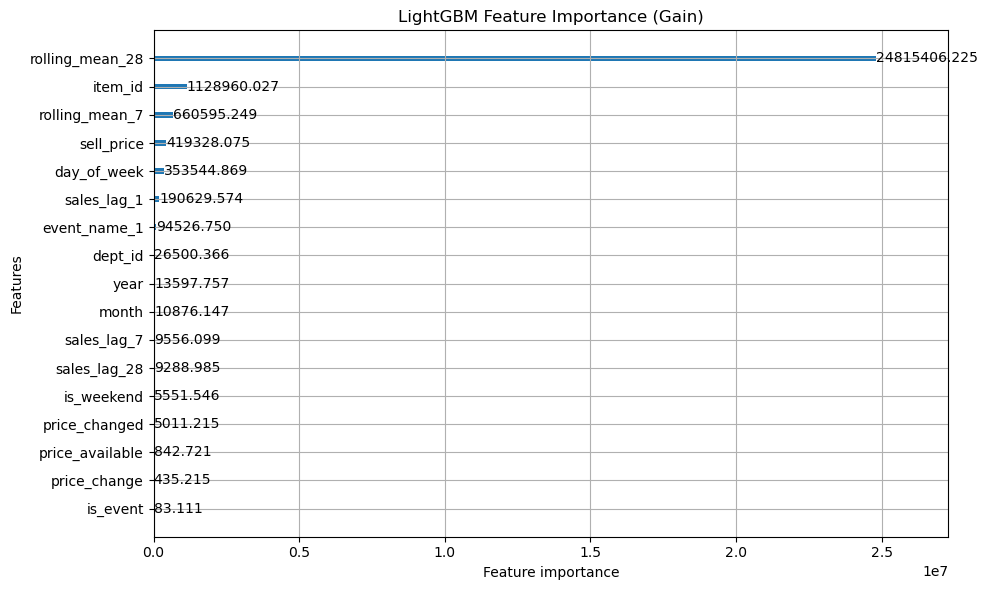

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Generate Predictions
# LightGBM automatically uses the best iteration (round 90) for prediction
y_pred = model.predict(X_valid)

# 2. Calculate final metrics
mae = mean_absolute_error(y_valid, y_pred)
rmse = np.sqrt(mean_squared_error(y_valid, y_pred))

print(f"Final Validation MAE: {mae:.4f} units")
print(f"Final Validation RMSE: {rmse:.4f} units")

# 3. Visualize Feature Importance
# 'gain' shows how much a feature contributed to reducing the error
ax = lgb.plot_importance(
    model, 
    max_num_features=20, 
    importance_type='gain', 
    figsize=(10, 6),
    title="LightGBM Feature Importance (Gain)"
)
plt.tight_layout()
plt.show()

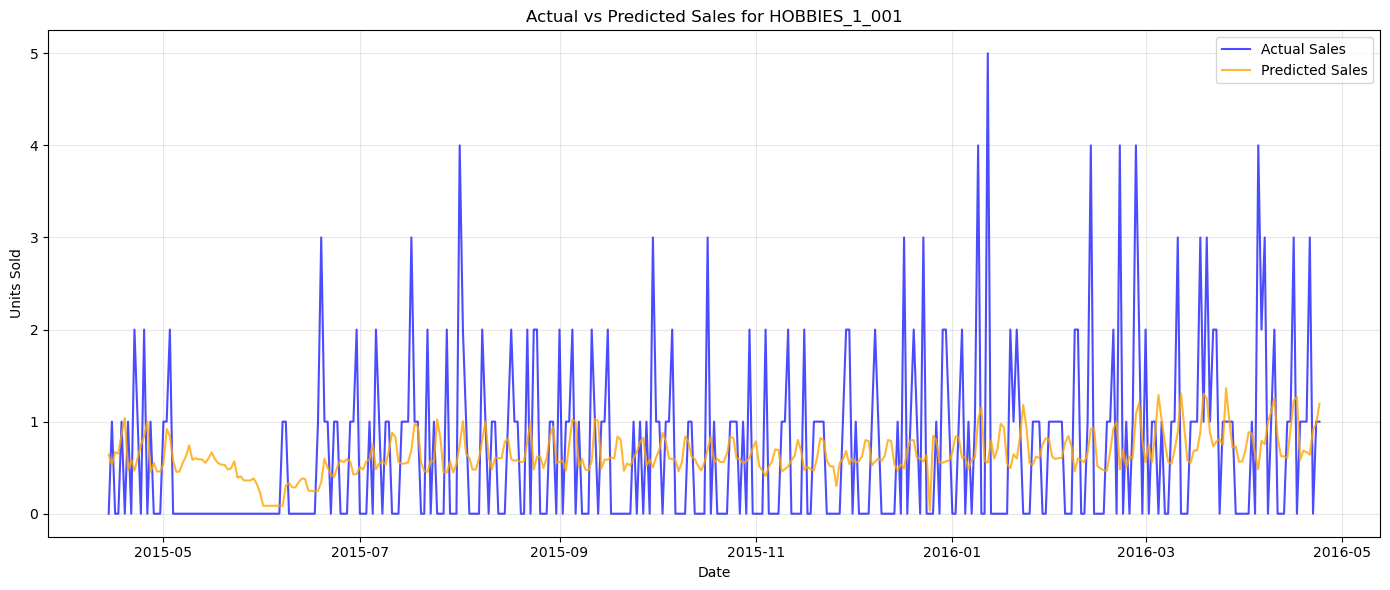

In [54]:
import matplotlib.pyplot as plt

# 1. Attach predictions to your original validation dataframe
valid_results = valid_df.copy()
valid_results['predicted_sales'] = y_pred

# 2. Pick an item to look at (let's grab the one with the most sales rows in validation)
sample_item = valid_results['item_id'].value_counts().index[0]
item_data = valid_results[valid_results['item_id'] == sample_item]

# 3. Plot the timeline
plt.figure(figsize=(14, 6))
plt.plot(item_data['date'], item_data['sales'], label='Actual Sales', alpha=0.7, color='blue')
plt.plot(item_data['date'], item_data['predicted_sales'], label='Predicted Sales', alpha=0.8, color='orange')

plt.title(f"Actual vs Predicted Sales for {sample_item}")
plt.ylabel("Units Sold")
plt.xlabel("Date")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Build the preprocess pipeline
We'll handle each feature group differently:
Feature group	        Treatment
Numerical	            Fill missing values using the training-set median
Product/store categories	Fill missing categories with "Unknown", then One-Hot Encode
Event categories	    Fill missing event slots with "No event", then One-Hot Encode
Important: We'll fit preprocessing on X_train only. Validation data must not influence the medians or the categories learned by the encoders.

# Creating the preprocessing pipeline 

# Fit preprocessing using training data only

# Establish our first baseline forecast
before training a machine-learning model, we need a baseline. Otherwise, we won't know whether our model actually improves forecasting.
We'll use weekly-naive forecasting.
What does that mean?
Retail demand often has a weekly pattern. For example, if a product sold 3 units last Monday, we can use those 3 units as our prediction for the same product on the following Monday.
Our existing feature sales_lag_7 already contains the previous week's sales for that product-store series.
So our baseline rule is:
\[
\widehat{sales}_t = sales_{t-7}
\]

This is a simple forecasting rule, not an ML model. It gives us a reference score to beat.

# Baseline Model — Weekly Naive Forecast

A WAPE of 100% means the total absolute error equals the total actual demand. Our baseline is slightly worse than that.
My honest assessment: the weekly-naive baseline is weak. But that's precisely why we're establishing a baseline—to see whether a better forecasting approach can improve upon it.

dataset has many zero-sales observations. So let's compare the weekly-naive method against an extremely simple baseline: predict zero sales for every observation.
Why? If most observations have zero demand, a zero-prediction baseline can perform surprisingly well under certain metrics.


# Correlation analysis
Relationship	        What it could tell us
sales vs sales_lag_1	Does yesterday's demand relate to today's demand?
sales vs sales_lag_7	Does demand repeat across weeks?
sales vs rolling averages	Does recent demand level help explain today's sales?
sales vs sell_price	    Is price associated with demand?
sales vs time features	Are there temporal patterns?

#  Finding 
- Historical demand is our strongest signal 
- rolling_mean_28: 0.632
- rolling_mean_7: 0.626
- sales_lag_1: 0.513
- sales_lag_7: 0.480
- sales_lag_28: 0.450
This supports using historical sales as major inputs to our forecasting model. Recent demand levels and previous observations appear informative.
There is also substantial correlation between the lag and rolling features themselves. That's understandable because they're all derived from historical sales. A regularized model can help control the effects of redundant predictors.

## Finding B — Price availability needs investigation
price_available has a correlation of 0.373, while sell_price has a negative correlation of −0.102.
But don't interpret this as proof that having a price causes sales to increase, or that increasing price necessarily reduces demand.
Remember, in our sample, every observation with a missing price had zero sales. Price availability may therefore act partly as a proxy for whether a product's pricing history had started. We'll need to be careful when interpreting this feature.

## Finding C — Weak correlation does not mean a feature is useless
These numbers measure individual monotonic relationships, not every way a feature could help prediction

In [ ]:
sns.pairplot(
    pairplot_df,
    corner=True,
    diag_kind="hist",
    plot_kws={
        "alpha": 0.25,
        "s": 12
    }
)

plt.suptitle(
    "Pair Plot — Sales and Demand Features",
    y=1.02
)

plt.show()

- according to the given plots we shouldnot use a linear model 
- we have zero heavy ,right skewed demand 
- Historical demand is informative, but the relationships are scattered
- Potential nonlinear interactions

In [72]:
import importlib.util

for package in ["lightgbm", "xgboost", "catboost"]:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Not installed'}")

lightgbm: Installed
xgboost: Installed
catboost: Not installed


In [74]:
import lightgbm as lgb

print("LightGBM version:", lgb.__version__)
print("Installation successful!")

LightGBM version: 4.7.0
Installation successful!


In [55]:
print("PI")

PI
